# Elbow Method for k-NN - Manual Plot, Cross-Validated

## Optimize the k-value for k-NN using the Elbow Method by manually plotting error rates for different k-values, ensuring a statistically sound selection without using built-in visualization libraries.

In [9]:
import numpy as np
from IPython.display import SVG, display

In [10]:
rng = np.random.default_rng(7)
n = 1500
X = np.vstack([rng.normal([0, 0], 1.4, (n, 2)), rng.normal([2, 2], 1.4, (n, 2))])
y = np.repeat([0, 1], n)

idx = rng.permutation(len(X)); s = int(0.8 * len(X))
X_train, y_train, X_test, y_test = X[idx[:s]], y[idx[:s]], X[idx[s:]], y[idx[s:]]
mu, sd = X_train.mean(0), X_train.std(0)
X_train, X_test = (X_train - mu) / sd, (X_test - mu) / sd
print(X_train.shape, X_test.shape)

(2400, 2) (600, 2)


In [11]:
def knn_errors(Xtr, ytr, Xva, yva, ks):
    D = np.sqrt(np.maximum(np.sum(Xva**2, 1)[:, None] + np.sum(Xtr**2, 1)[None, :] - 2 * Xva @ Xtr.T, 0))
    nn = np.argsort(D, axis=1)[:, :max(ks)]           
    votes = np.cumsum(ytr[nn], axis=1)                  
    errs = []
    for k in ks:
        pred = (votes[:, k - 1] > k / 2).astype(int)   
        errs.append(np.mean(pred != yva))
    return np.array(errs)

In [12]:
ks = list(range(1, 102, 2))                            
folds = np.array_split(rng.permutation(len(X_train)), 10)

fold_err = []
for f in folds:
    tr = np.setdiff1d(np.arange(len(X_train)), f)
    fold_err.append(knn_errors(X_train[tr], y_train[tr], X_train[f], y_train[f], ks))
fold_err = np.array(fold_err)                          

mean_err = fold_err.mean(0)
se_err = fold_err.std(0, ddof=1) / np.sqrt(len(folds))
for k, m, s_ in list(zip(ks, mean_err, se_err))[:6]:
    print(f'k={k:2d}  error={m:.4f} +- {s_:.4f}')

k= 1  error=0.2092 +- 0.0099
k= 3  error=0.1871 +- 0.0079
k= 5  error=0.1729 +- 0.0063
k= 7  error=0.1663 +- 0.0065
k= 9  error=0.1650 +- 0.0060
k=11  error=0.1642 +- 0.0051


In [13]:
k_min = ks[int(np.argmin(mean_err))]

i = int(np.argmin(mean_err))
limit = mean_err[i] + se_err[i]
k_1se = max(k for k, m in zip(ks, mean_err) if m <= limit)

kx = (np.array(ks) - ks[0]) / (ks[-1] - ks[0])
ey = (mean_err - mean_err.min()) / (mean_err.max() - mean_err.min())
p1, p2 = np.array([kx[0], ey[0]]), np.array([kx[-1], ey[-1]])
line = (p2 - p1) / np.linalg.norm(p2 - p1)
pts = np.c_[kx, ey] - p1
dist = np.abs(pts[:, 0] * line[1] - pts[:, 1] * line[0])  
k_elbow = ks[int(np.argmax(dist))]

print('Minimum error k :', k_min)
print('1-SE rule k     :', k_1se)
print('Elbow k         :', k_elbow)

Minimum error k : 47
1-SE rule k     : 63
Elbow k         : 27


In [14]:
def svg_plot(x, y, yerr, marks, title, xlabel, ylabel, W=720, H=440):
    L, R, T, B = 70, 30, 50, 60                             
    x0, x1 = min(x), max(x)
    y0, y1 = min(y - yerr) - 0.005, max(y + yerr) + 0.005
    sx = lambda v: L + (v - x0) / (x1 - x0) * (W - L - R)
    sy = lambda v: H - B - (v - y0) / (y1 - y0) * (H - T - B)
    o = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{W}" height="{H}" font-family="sans-serif" font-size="12">',
         f'<rect width="{W}" height="{H}" fill="white"/>',
         f'<text x="{W/2}" y="28" text-anchor="middle" font-size="16" font-weight="bold">{title}</text>']
    for t in np.linspace(y0, y1, 6):                         # y grid + ticks
        o.append(f'<line x1="{L}" x2="{W-R}" y1="{sy(t)}" y2="{sy(t)}" stroke="#e5e5e5"/>')
        o.append(f'<text x="{L-8}" y="{sy(t)+4}" text-anchor="end">{t:.3f}</text>')
    for t in [int(x0)] + list(range(20, int(x1) + 1, 20)):                # x ticks
        o.append(f'<text x="{sx(t)}" y="{H-B+18}" text-anchor="middle">{t}</text>')
    o.append(f'<line x1="{L}" x2="{W-R}" y1="{H-B}" y2="{H-B}" stroke="black"/>')
    o.append(f'<line x1="{L}" x2="{L}" y1="{T}" y2="{H-B}" stroke="black"/>')
    o.append(f'<text x="{W/2}" y="{H-14}" text-anchor="middle">{xlabel}</text>')
    o.append(f'<text x="18" y="{H/2}" text-anchor="middle" transform="rotate(-90 18 {H/2})">{ylabel}</text>')
    for a, b, e in zip(x, y, yerr):                          # error bars (+-1 SE)
        o.append(f'<line x1="{sx(a)}" x2="{sx(a)}" y1="{sy(b-e)}" y2="{sy(b+e)}" stroke="#9bb7d4"/>')
    pts = ' '.join(f'{sx(a):.1f},{sy(b):.1f}' for a, b in zip(x, y))
    o.append(f'<polyline points="{pts}" fill="none" stroke="#1f5fa8" stroke-width="2"/>')
    for a, b in zip(x, y):
        o.append(f'<circle cx="{sx(a)}" cy="{sy(b)}" r="2.5" fill="#1f5fa8"/>')
    for j, (kv, name, col) in enumerate(marks):              # chune hue k + legend
        v = y[list(x).index(kv)]
        o.append(f'<line x1="{sx(kv)}" x2="{sx(kv)}" y1="{T}" y2="{H-B}" stroke="{col}" stroke-dasharray="5,4"/>')
        o.append(f'<circle cx="{sx(kv)}" cy="{sy(v)}" r="6" fill="none" stroke="{col}" stroke-width="2"/>')
        o.append(f'<text x="{W-R-5}" y="{T+16+16*j}" text-anchor="end" fill="{col}">{name}: k={kv}</text>')
    o.append('</svg>')
    return '\n'.join(o)

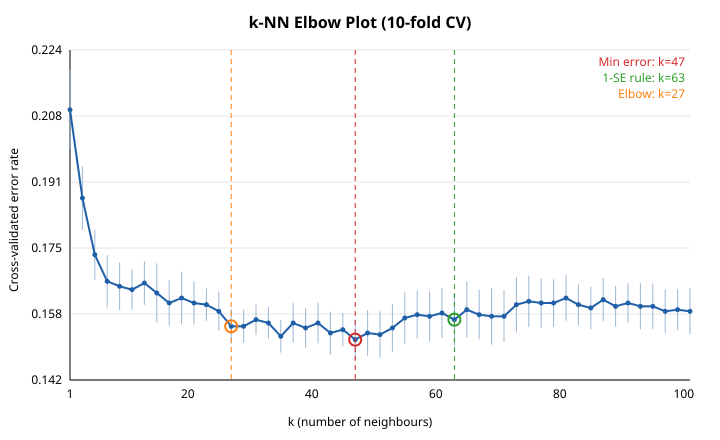

11901

In [15]:
marks = [(k_min, 'Min error', '#d62728'), (k_1se, '1-SE rule', '#2ca02c'), (k_elbow, 'Elbow', '#ff7f0e')]
svg = svg_plot(np.array(ks), mean_err, se_err, marks,
               'k-NN Elbow Plot (10-fold CV)', 'k (number of neighbours)', 'Cross-validated error rate')
display(SVG(svg))
open('elbow_plot.svg', 'w').write(svg)                       # file ke roop me bhi save

In [16]:
print(f"{'Rule':12s} {'k':>3s} {'CV error':>9s} {'Test error':>11s}")
for name, k in [('Min error', k_min), ('1-SE rule', k_1se), ('Elbow', k_elbow), ('k=1', 1)]:
    cv = mean_err[ks.index(k)]
    te = knn_errors(X_train, y_train, X_test, y_test, [k])[0]
    print(f'{name:12s} {k:3d} {cv:9.4f} {te:11.4f}')

Rule           k  CV error  Test error
Min error     47    0.1517      0.1633
1-SE rule     63    0.1567      0.1533
Elbow         27    0.1550      0.1700
k=1            1    0.2092      0.2367


## Analysis
(Apne run ke numbers dekhke yahan 2-3 line apne words me likho.)

- **k=1** me error sabse zyada hota hai (~21%) kyunki model noise ko yaad kar leta hai (overfit). k badhne pe error tezi se girta hai, phir lagbhag flat ho jaata hai.
- **Elbow (k=27)** wo point hai jahan girna slow ho jaata hai. Maine ise geometric tareeke se nikala: curve ko normalize karke first-last point ki line se sabse door wala point.
- **Minimum error (k=47)** sirf ek noisy minimum hai. Error bars (+-1 SE) dikhate hain ki k=25 se k=75 tak ke errors statistically lagbhag same hain, isliye "sabse kam error wala k" fragile choice hai.
- **1-SE rule (k=63):** minimum error ke 1 SE ke andar sabse bada k (sabse smooth model) chuno. Ye overfit se bachata hai.
- **Test set** (600 points) ko tuning me use nahi kiya. Test errors (15.3% se 17.0%) ke farak noise ke andar hain (test error ka SE lagbhag 1.5% hai), isliye ye nahi kehna chahiye ki koi ek rule test pe "jeeta".
- Is data me flat region chauda hai (25 se 75), isliye koi bhi k us range ka theek hai. Elbow method hamesha clear elbow nahi deta, aur overlapping data me CV + SE wale rules zyada bharosemand hain.